> **Archived record.** This is the notebook exactly as executed on 5 November 2026 to produce the results in
> `data/results/bfd_results.csv`, kept with its outputs as a provenance record. Only the API token has been
> removed. To reproduce or rerun the experiment, use `notebooks/BFD_quantum_demonstration.ipynb`, which implements
> the same method and reproduces every figure and table from the recorded data.


# Bounded Feasibility Demonstration
## Penalty-weight calibration for a reverse logistics QUBO on D-Wave quantum hardware

**Thesis:** Quantum Computing for Circular Supply Chains: Application Areas, Adoption Barriers, and Enabling Conditions  
**Author:** Ismail Zahoor, Arcada University of Applied Sciences  
**Appendix to:** Chapter 3.4 (method) and Chapter 4 (results)  
**Date executed:** 05.11.2026

**Quantum hardware used:** D-Wave Advantage_system6 — 5,612 qubits, Pegasus topology, NA-WEST-1 region  
**Hybrid solver used:** hybrid_binary_quadratic_model_version2p  
**Date executed:** 5 November 2026

---

### What this notebook establishes

Chapter 3.4 tests one proposition: that **solution quality depends materially on how a problem is formulated**,
not only on which solver runs it. If true, formulation expertise is an adoption barrier that improved hardware
does not remove — a finding about adoption, not about quantum speed.

The notebook proceeds in eight steps:

|Step |Action |Why it is necessary |
|---|---|---|
| 1 | Install libraries | Dependencies for optimization, hardware access, and plotting |
| 2 | Configure API token | Authenticates against D-Wave Leap |
| 3 | Build the problem and solve it exactly | Establishes the **known optimum** all later results are measured against |
| 4 | Re-express the problem as a QUBO | Quantum annealers accept only this format; constraints become cost penalties |
| 5 | Verify the QUBO | Proves the translation is faithful before any hardware time is spent |
| 6 | Connect to D-Wave | Confirms credentials and records which processor is used |
| 7 | Run the experiment | Varies penalty weight only, holding problem, solver, and hardware constant |
| 8 | Produce figures and tables | Chapter 4 outputs |

### Scope and limitations, stated in advance

This is **not a benchmarking study and makes no claim of quantum advantage.** The instances contain 27 to 105
binary variables; classical methods solve them exactly in milliseconds and are expected to outperform the
quantum hardware throughout. The quantity under study is sensitivity to formulation, not solver speed.

### Reproducibility

- All problem instances are generated from a **fixed random seed (42)**, so they are identical on every run
- The classical optimum is computed exactly, not approximated, giving a stable reference point
- Each experimental condition is repeated 20 times, because quantum annealing is probabilistic
- Every run records the processor ID, embedding statistics, and timing to `bfd_results.csv`

A reader re-executing this notebook will obtain identical classical results. Quantum results will differ in
detail — the hardware is stochastic and subject to calibration drift — but the pattern across penalty weights
should reproduce.
Results are hardware-specific. This execution used Advantage_system6; the earlier September pilot ran on
Advantage_system4, which is no longer offered. Quantum results should be compared within a single processor,
not across the two.


### Prerequisites

A D-Wave Leap account with solver access. Copy the **Solver API Token**  from the Leap
dashboard with the correct project selected in the project switcher, as tokens are project-specific.

Run all cells in order, top to bottom. Steps 1 through 5 consume no solver time.

---
## Step 1 — Install dependencies

- **`dwave-ocean-sdk`** — D-Wave's toolkit: `dimod` constructs the problem, `dwave-system` communicates with
  the hardware, `dwave-samplers` provides classical simulated annealing that runs locally at no cost
- **`ortools`** — Google's constraint solver, used to compute the exact classical optimum
- **`pandas`, `matplotlib`** — results handling and figures

Colab may display a **"Restart session"** warning after installation. If it does, restart, then re-run this
cell and continue. Installed packages survive a restart; variables do not.

In [ ]:
!pip install --quiet dwave-ocean-sdk ortools pandas matplotlib
print("Done. If Colab shows a Restart warning, restart and re-run this cell.")

Done. If Colab shows a Restart warning, restart and re-run this cell.


---
## Step 2 — Credentials and imports

Paste your Solver API Token where indicated. The token authenticates every later call to D-Wave.

**If sharing this notebook**, replace the literal token with Colab Secrets so no credential is stored in the
file: click the key icon in the left sidebar, add a secret named `DWAVE_API_TOKEN`, enable notebook access,
and substitute:

```python
from google.colab import userdata
os.environ["DWAVE_API_TOKEN"] = userdata.get("DWAVE_API_TOKEN")
```

This cell also fixes plotting defaults so every figure in the thesis shares one visual style.

In [ ]:
import os
os.environ["DWAVE_API_TOKEN"] = "PASTE_YOUR_OWN_TOKEN_HERE"   # <-- paste here

import itertools, time, warnings
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("OK" if os.environ["DWAVE_API_TOKEN"] != "PASTE_YOUR_OWN_TOKEN_HERE" else "Token looks wrong")

OK


---
## Step 3 — The circular supply chain problem, and its exact solution

### The decision

A company collects returned electronics from a number of collection points and must decide which sorting
facilities to open, and which collection point feeds which facility. Opening a facility incurs a fixed cost;
transporting returns incurs a distance- and volume-dependent cost. Too few facilities raises transport cost;
too many raises fixed cost.

This is reverse logistics network design — a genuine circular supply chain decision, not a generic
optimization exercise. It was chosen over vehicle routing because it encodes in roughly `m x n + n` binary
variables rather than `n²`, and because small instances admit a provable optimum.

### Decision variables

- `y_j = 1` if facility *j* is opened, `0` otherwise
- `x_ij = 1` if collection point *i* is assigned to facility *j*, `0` otherwise

### Constraints

1. Every collection point is assigned to exactly one facility
2. No collection point may be assigned to a facility that is not open

### Objective

Minimize the sum of facility opening costs and transport costs.

### Instances

| Instance | Collection points | Facilities | Binary variables |
|---|---|---|---|
| A | 8 | 3 | 27 |
| B | 12 | 4 | 52 |
| C | 20 | 5 | 105 |

Instance B carries the headline result: the embedding is comfortable at 52 variables and the penalty effect
spans its full range. A and C serve as a robustness check across problem size.

### Why the exact solution comes first

Every subsequent result is reported as an **optimality gap** — the percentage by which a solution exceeds the
true minimum cost. Without this reference, quantum results could only be compared against one another, which
would demonstrate nothing. OR-Tools CP-SAT returns the provable optimum here in milliseconds. Costs are scaled
to whole cents because CP-SAT operates on integers; the scaling is exact.

**Expected output:** EUR 7,571 (A), EUR 8,253 (B), EUR 14,154 (C). These values are deterministic and should
reproduce exactly. The solve times in the final column are the honest classical baseline against which no
quantum result in this notebook competes.

In [ ]:
INSTANCES = {"A": (8, 3), "B": (12, 4), "C": (20, 5)}

def build_instance(name, seed=42):
    m, n = INSTANCES[name]
    rng = np.random.default_rng(seed)
    points = rng.uniform(0, 100, size=(m, 2))
    facilities = rng.uniform(20, 80, size=(n, 2))
    volumes = rng.integers(50, 200, size=m)
    cost_per_unit_km = 0.15
    open_cost = rng.integers(800, 2000, size=n)
    dist = np.linalg.norm(points[:, None, :] - facilities[None, :, :], axis=2)
    transport = dist * volumes[:, None] * cost_per_unit_km
    return {"name": name, "m": m, "n": n, "transport": transport,
            "open_cost": open_cost, "volumes": volumes,
            "points": points, "facilities": facilities}

def decode(sample, inst):
    """Turn switch settings into a business answer, and check the rules held."""
    m, n = inst["m"], inst["n"]
    assign, violations = {}, []
    for i in range(m):
        chosen = [j for j in range(n) if sample.get(f"x_{i}_{j}", 0) == 1]
        if len(chosen) != 1:
            violations.append(f"point {i} -> {len(chosen)} facilities")
        if chosen:
            assign[i] = chosen[0]
    opened = {j for j in range(n) if sample.get(f"y_{j}", 0) == 1}
    for i, j in assign.items():
        if j not in opened:
            violations.append(f"point {i} -> closed facility {j}")
    cost = sum(inst["open_cost"][j] for j in opened)
    cost += sum(inst["transport"][i][j] for i, j in assign.items())
    return {"assignment": assign, "opened": sorted(opened), "cost": float(cost),
            "feasible": len(violations) == 0, "violations": violations}

def solve_exact(inst):
    """Exact optimum via OR-Tools CP-SAT. Costs scaled to whole cents (exact)."""
    from ortools.sat.python import cp_model
    m, n = inst["m"], inst["n"]
    SCALE = 100
    transport = np.rint(inst["transport"] * SCALE).astype(int)
    open_cost = np.rint(np.asarray(inst["open_cost"], dtype=float) * SCALE).astype(int)
    model = cp_model.CpModel()
    x = {(i, j): model.NewBoolVar(f"x_{i}_{j}") for i in range(m) for j in range(n)}
    y = {j: model.NewBoolVar(f"y_{j}") for j in range(n)}
    for i in range(m):
        model.AddExactlyOne(x[(i, j)] for j in range(n))
        for j in range(n):
            model.Add(x[(i, j)] <= y[j])
    model.Minimize(sum(int(open_cost[j]) * y[j] for j in range(n))
                   + sum(int(transport[i][j]) * x[(i, j)]
                         for i in range(m) for j in range(n)))
    solver = cp_model.CpSolver()
    t0 = time.perf_counter()
    status = solver.Solve(model)
    elapsed = time.perf_counter() - t0
    assert status == cp_model.OPTIMAL, f"CP-SAT status {status}"
    sample = {f"x_{i}_{j}": solver.Value(x[(i, j)]) for i in range(m) for j in range(n)}
    sample.update({f"y_{j}": solver.Value(y[j]) for j in range(n)})
    r = decode(sample, inst)
    r["wall_seconds"] = elapsed
    return r

OPTIMA, rows = {}, []
for name in INSTANCES:
    inst = build_instance(name); r = solve_exact(inst)
    OPTIMA[name] = r["cost"]
    rows.append({"Instance": name, "Variables": inst["m"]*inst["n"]+inst["n"],
                 "Optimum (EUR)": round(r["cost"]), "Opened": str(r["opened"]),
                 "Solve time (ms)": round(r["wall_seconds"]*1000, 1)})
display(pd.DataFrame(rows))

,Instance,Variables,Optimum (EUR),Opened,Solve time (ms)
0,A,27,7571,[1],9.2
1,B,52,8253,"[0, 3]",12.7
2,C,105,14154,"[2, 3]",27.7


---
## Step 4 — Translating the problem into QUBO form

A quantum annealer accepts exactly one input format: a **QUBO**, or Quadratic Unconstrained Binary
Optimization problem. The name states the limitation precisely.

- **Binary** — every variable is on or off
- **Quadratic** — costs attach to single variables or to pairs, never to triples
- **Unconstrained** — **there is no mechanism for expressing a rule that must hold**

### How constraints survive this restriction

They are converted into financial penalties. Rather than forbidding a violation, the formulation makes it
expensive. The annealer searches for the lowest total cost, so a sufficiently large penalty makes violation
unattractive.

| Constraint | Penalty term added to the objective |
|---|---|
| Each collection point assigned exactly once | `A x (number assigned − 1)²` |
| No assignment to a closed facility | `B x x_ij x (1 − y_j)` |

Both expand into the pairwise terms a QUBO permits, using the identity `x² = x` for binary variables. The
algebraic expansion is commented in the code.

### The problem this creates, which is the subject of this study

Nothing in the business problem determines how large the penalties should be.

- **Set too low** — the solver violates constraints to reduce cost, returning solutions that are cheap but
  invalid
- **Set too high** — the penalty terms dominate the arithmetic, so the solver prioritizes constraint
  satisfaction and becomes insensitive to cost, returning solutions that are valid but expensive

`penalty_scale` is the parameter controlling penalty magnitude. **It is the only quantity this experiment
varies.** Everything else — problem, instance, solver, hardware, number of reads — is held constant, so that
observed variation is attributable to the formulation choice.

In [ ]:
def build_qubo(inst, penalty_scale=2.0):
    m, n = inst["m"], inst["n"]
    transport, open_cost = inst["transport"], inst["open_cost"]
    A = penalty_scale * float(transport.max()) * n
    B = penalty_scale * float(max(transport.max(), open_cost.max()))
    Q = {}
    def add(u, v, w):
        key = (u, v) if u <= v else (v, u)
        Q[key] = Q.get(key, 0.0) + w
    def x(i, j): return f"x_{i}_{j}"
    def y(j): return f"y_{j}"

    for j in range(n):
        add(y(j), y(j), float(open_cost[j]))
    for i in range(m):
        for j in range(n):
            add(x(i, j), x(i, j), float(transport[i][j]))

    offset = 0.0
    for i in range(m):                                  # rule 1: assign exactly once
        for j in range(n):
            add(x(i, j), x(i, j), -A)
        for j, k in itertools.combinations(range(n), 2):
            add(x(i, j), x(i, k), 2 * A)
        offset += A

    for i in range(m):                                  # rule 2: no closed facility
        for j in range(n):
            add(x(i, j), x(i, j), B)
            add(x(i, j), y(j), -B)
    return Q, offset, {"A": A, "B": B}

---
## Step 5 — Verifying the translation before spending hardware time

If the QUBO encodes a different problem than the original formulation, every subsequent measurement is
meaningless. This step establishes that it does not.

**Method.** Solve the QUBO using classical simulated annealing, which runs locally and requires no account. If
it reaches the exact optimum found in Step 3, the translation is faithful.

The `summarize` function defined here is used by every solver in the notebook. It selects the lowest-cost
*valid* solution and reports what proportion of samples satisfied the constraints. This distinction is
essential: because constraints are enforced by penalties rather than hard restrictions, a solver can return a
solution that scores well internally yet violates the rules. Such solutions are recorded as infeasible and
never counted as results.

**Expected output:** EUR 7,571 on instance A, matching Step 3, followed by `MATCH`. If `MISMATCH` appears, the
formulation is incorrect and no further cell should be run.

Note that the feasible-read proportion is already well below 100% at this penalty setting. That is the first
indication of the effect this study measures.

In [ ]:
import dimod
from dwave.samplers import SimulatedAnnealingSampler

def summarize(sampleset, inst):
    """Best valid solution, plus how many reads were valid."""
    best, feasible_reads, total_reads = None, 0, 0
    for rec in sampleset.data(["sample", "energy", "num_occurrences"]):
        d = decode(rec.sample, inst)
        total_reads += rec.num_occurrences
        if d["feasible"]:
            feasible_reads += rec.num_occurrences
            if best is None or d["cost"] < best["cost"]:
                best = d
    if best is None:
        best = decode(sampleset.first.sample, inst)
    return best, feasible_reads, total_reads

inst = build_instance("A")
Q, offset, w = build_qubo(inst, penalty_scale=0.25)
bqm = dimod.BinaryQuadraticModel.from_qubo(Q, offset=offset)
ss = SimulatedAnnealingSampler().sample(bqm, num_reads=1000, seed=42)
best, fr, tr = summarize(ss, inst)

print(f"Classical optimum: EUR {OPTIMA['A']:,.0f}")
print(f"QUBO best found:   EUR {best['cost']:,.0f}  (facilities {best['opened']})")
print(f"Valid reads:       {fr}/{tr}")
print("\nMATCH — same problem, correctly translated."
      if abs(best["cost"] - OPTIMA["A"]) < 1 else "\nMISMATCH — stop here.")

Classical optimum: EUR 7,571
QUBO best found:   EUR 7,571  (facilities [1])
Valid reads:       182/1000

MATCH — same problem, correctly translated.


---
## Step 6 — Connecting to D-Wave Leap

Listing available solvers consumes no solver time. The listing should show at least one QPU with a name
beginning `Advantage`, and at least one hybrid solver. The presence of hybrid solvers confirms access through
an institutional project rather than a trial account.

### Why the processor is pinned by name

The default solver can change between sessions. Which processor produced a given result is a reportable fact,
so the notebook selects it explicitly and records `chip_id` on every run. A claim in the thesis that results
came from a particular processor must be supported by the data file.

### Embedding

The qubits on a quantum annealing processor are not all physically connected. This problem requires couplings
the hardware does not provide, so several physical qubits are chained together to represent one logical
variable. `EmbeddingComposite` computes this mapping automatically.

Two consequences are recorded on every run. Chaining consumes more physical qubits than the problem has
variables, and chains can **break** — the qubits within a chain disagree — which corrupts the result. Both the
qubit count and the chain-break fraction appear in the output data.

**Record the chip ID printed here in the thesis methodology section.**

In [ ]:
from dwave.cloud import Client
from dwave.system import DWaveSampler, EmbeddingComposite, LeapHybridSampler

with Client.from_config() as client:
    solvers = client.get_solvers()
    qpus   = [s.name for s in solvers if s.properties.get("category") == "qpu"]
    hybrid = [s.name for s in solvers if s.properties.get("category") == "hybrid"]
print("QPUs:   ", qpus)
print("Hybrid: ", hybrid)

QPU_NAME    = qpus[0]
qpu         = DWaveSampler(solver=QPU_NAME)
qpu_sampler = EmbeddingComposite(qpu)
CHIP_ID     = qpu.properties.get("chip_id", "unknown")
print(f"\nChip: {CHIP_ID} | {len(qpu.nodelist)} qubits | "
      f"{qpu.properties['topology']['type']} topology")

QPUs:    ['Advantage_system6']
Hybrid:  ['hybrid_binary_quadratic_model_version2p', 'hybrid_discrete_quadratic_model_version1p', 'hybrid_constrained_quadratic_model_version1p', 'stride_hybrid_solver']

Chip: Advantage_system6 | 5612 qubits | pegasus topology


---
## Step 7 — Experimental procedure

### Design

One factor varies: `penalty_scale`, across six levels (0.1, 0.25, 0.5, 1.0, 2.0, 4.0). The instance, solver,
processor, read count, and annealing time are held constant within each arm. Observed variation is therefore
attributable to the formulation parameter.

### Replication

Quantum annealing is probabilistic: identical submissions return different results. A single run per condition
cannot distinguish a systematic effect from random variation. Each condition is therefore repeated 20 times,
permitting a mean and a dispersion measure to be reported.

### Variables recorded

One row per solver call, written to `bfd_results.csv`:

| Field | Purpose |
|---|---|
| `instance`, `n_variables` | Identifies the problem and its size |
| `solver`, `chip_id` | Identifies the solver and processor |
| `penalty_scale`, `penalty_A`, `penalty_B` | The manipulated factor and derived coefficients |
| `replication` | Supports mean and dispersion |
| `best_cost`, `optimality_gap_pct` | The outcome measures |
| `feasible`, `feasible_fraction` | Whether constraints held, and for what share of samples |
| `chain_strength`, `chain_break_fraction`, `max_chain_length`, `physical_qubits` | Embedding diagnostics |
| `qpu_access_time_us`, `charge_time_us`, `wall_seconds` | Timing, reported as context only |

Timing is reported as context, never as a performance claim, consistent with Chapter 3.4.

In [ ]:
def run_one(inst, optimum, solver, penalty_scale, replication,
            num_reads=1000, annealing_time=20, chain_strength=None,
            qpu_sampler=None, hybrid_sampler=None, seed=None):
    Q, offset, w = build_qubo(inst, penalty_scale=penalty_scale)
    bqm = dimod.BinaryQuadraticModel.from_qubo(Q, offset=offset)

    row = {"instance": inst["name"], "n_variables": inst["m"]*inst["n"]+inst["n"],
           "solver": solver, "penalty_scale": penalty_scale,
           "penalty_A": w["A"], "penalty_B": w["B"], "replication": replication,
           "chip_id": "", "num_reads": np.nan, "annealing_time_us": np.nan,
           "chain_strength": np.nan, "chain_break_fraction": np.nan,
           "max_chain_length": np.nan, "physical_qubits": np.nan,
           "qpu_access_time_us": np.nan, "charge_time_us": np.nan}

    t0 = time.perf_counter()
    if solver == "sa":
        ss = SimulatedAnnealingSampler().sample(bqm, num_reads=num_reads, seed=seed)
        row["num_reads"] = num_reads
    elif solver.startswith("qpu"):
        kw = dict(num_reads=num_reads, annealing_time=annealing_time,
                  label=f"BFD-{inst['name']}-p{penalty_scale}-r{replication}",
                  return_embedding=True)
        if chain_strength is not None:
            kw["chain_strength"] = chain_strength
        ss = qpu_sampler.sample(bqm, **kw)
        row["num_reads"] = num_reads
        row["annealing_time_us"] = annealing_time
    elif solver == "hybrid":
        ss = hybrid_sampler.sample(
            bqm, label=f"BFD-{inst['name']}-p{penalty_scale}-r{replication}")
    else:
        raise ValueError(solver)
    row["wall_seconds"] = time.perf_counter() - t0

    best, fr, tr = summarize(ss, inst)
    row["best_cost"] = best["cost"]
    row["feasible"] = best["feasible"]
    row["optimality_gap_pct"] = ((best["cost"] - optimum) / optimum * 100
                                 if best["feasible"] else np.nan)
    row["feasible_fraction"] = fr / tr if tr else 0.0

    info = ss.info or {}
    timing = info.get("timing", {}) or {}
    # QPU nests timing under "timing"; hybrid reports it at the top level.
    row["qpu_access_time_us"] = timing.get("qpu_access_time", np.nan)
    row["charge_time_us"] = info.get("charge_time", timing.get("charge_time", np.nan))
    if solver.startswith("qpu"):
        ectx = info.get("embedding_context", {}) or {}
        emb = ectx.get("embedding", {})
        if emb:
            chains = [len(v) for v in emb.values()]
            row["physical_qubits"] = sum(chains)
            row["max_chain_length"] = max(chains)
        row["chain_strength"] = ectx.get("chain_strength", np.nan)
        if "chain_break_fraction" in ss.record.dtype.names:
            row["chain_break_fraction"] = float(np.average(
                ss.record.chain_break_fraction, weights=ss.record.num_occurrences))
    return row

def run_sweep(inst, optimum, solver, penalties, replications, **kw):
    out = []
    for ps in penalties:
        for rep in range(replications):
            seed = 1000*rep + int(ps*100) if solver == "sa" else None
            out.append(run_one(inst, optimum, solver, ps, rep, seed=seed, **kw))
    return pd.DataFrame(out)

PENALTIES, REPLICATIONS = [0.1, 0.25, 0.5, 1.0, 2.0, 4.0], 20
results = []

---
## Step 8 — Single verification run on quantum hardware

A single submission, consuming approximately one second of QPU time, confirming that the complete pipeline
functions on physical hardware before the full experiment is committed. Problems with credentials, embedding,
or logging surface here at minimal cost.

**This is the first cell that consumes the solver allowance.**

**If this cell succeeds**, the feasibility question posed by Chapter 3.4 is answered: a circular supply chain
problem has been formulated, encoded, and solved on quantum hardware, with the result measured against a known
optimum. Everything that follows is replication to generate sufficient data for analysis.

**If it fails**, check in order: the token was pasted in full; the correct project was selected when it was
copied; Step 6 listed a QPU. An authentication error indicates the token. An embedding error indicates the
problem exceeds what the processor can accommodate, which is itself a reportable finding.

Note the ratio of physical qubits to logical variables in the output. It quantifies the embedding overhead
that separates problem size from hardware requirement.

In [ ]:
row = run_one(build_instance("A"), OPTIMA["A"], "qpu", 0.25, 0,
              num_reads=1000, qpu_sampler=qpu_sampler)
row["chip_id"] = CHIP_ID
print(f"Chip:            {row['chip_id']}")
print(f"Best cost:       EUR {row['best_cost']:,.0f}  (optimum {OPTIMA['A']:,.0f})")
print(f"Optimality gap:  {row['optimality_gap_pct']:.1f}%")
print(f"Valid reads:     {row['feasible_fraction']:.0%}")
print(f"Qubits used:     {row['physical_qubits']:.0f} for 27 variables, "
      f"longest chain {row['max_chain_length']:.0f}")
print(f"Chain breaks:    {row['chain_break_fraction']:.1%}")
print(f"QPU time:        {row['qpu_access_time_us']/1000:.1f} ms")

Chip:            Advantage_system6
Best cost:       EUR 7,571  (optimum 7,571)
Optimality gap:  0.0%
Valid reads:     4%
Qubits used:     32 for 27 variables, longest chain 2
Chain breaks:    0.0%
QPU time:        112.7 ms


---
## Step 9 — Experimental arms

Run each arm separately and allow it to complete before starting the next.

### Arm 1 — Classical baseline (no solver time)

All three instances under simulated annealing. This costs nothing, provides the comparison line for Figure 1,
and validates the experimental logic before hardware time is committed. Approximately 5 to 10 minutes on
Colab's processor. The read count matches the quantum arm so the two are directly comparable.

### Arm 2 — Quantum hardware, instance B

The headline result. Approximately 25 seconds of QPU time, though wall-clock time is longer because each
submission queues.

### Arm 3 — Control for chain strength

`EmbeddingComposite` sets chain strength automatically, scaled to the magnitude of the QUBO coefficients.
Raising the penalty raises those coefficients, so chain strength covaries with the manipulated factor and the
experiment would otherwise alter two quantities simultaneously.

This arm fixes chain strength across all six penalty settings. If the degradation persists under a constant
chain strength, it is attributable to the penalty encoding rather than to an embedding artifact. This
forecloses the most direct objection to the central finding.

### Arm 4 — Hybrid solver

The hybrid solver combines classical algorithms with QPU calls and represents what an organization would
realistically deploy. A five-second minimum applies per submission, so three repetitions per condition. This
arm establishes whether penalty sensitivity persists in production tooling, which bears directly on the
adoption argument.

### Arm 5 — Robustness across problem size (optional)

Instances A and C on hardware, demonstrating that the pattern is not specific to one problem size. Instance C
at 105 variables also indicates where embedding strain begins. The headline result does not depend on this arm.

### Data file

`bfd_results.csv` contains one row per solver call and constitutes the raw data appendix. Download it from the
folder icon in Colab's left sidebar.

In [ ]:
# ARM 1 — classical baseline, all instances. Free. 5-10 min.
t0 = time.time()
for name in INSTANCES:
    inst = build_instance(name)
    for ps in PENALTIES:
        df = run_sweep(inst, OPTIMA[name], "sa", [ps], REPLICATIONS, num_reads=1000)
        results.append(df)
        g = df["optimality_gap_pct"].mean()
        print(f"  {name} penalty {ps:<5} -> "
              f"{'no feasible solution' if pd.isna(g) else f'mean gap {g:5.1f}%'}"
              f"   [{time.time()-t0:.0f}s]")

  A penalty 0.1   -> no feasible solution   [15s]
  A penalty 0.25  -> mean gap   0.0%   [30s]
  A penalty 0.5   -> mean gap   0.0%   [44s]
  A penalty 1.0   -> mean gap   0.0%   [59s]
  A penalty 2.0   -> mean gap   0.9%   [74s]
  A penalty 4.0   -> mean gap   3.1%   [88s]
  B penalty 0.1   -> no feasible solution   [113s]
  B penalty 0.25  -> mean gap   0.1%   [141s]
  B penalty 0.5   -> mean gap   6.6%   [168s]
  B penalty 1.0   -> mean gap  16.6%   [196s]
  B penalty 2.0   -> mean gap  20.8%   [225s]
  B penalty 4.0   -> mean gap  21.6%   [253s]
  C penalty 0.1   -> no feasible solution   [311s]
  C penalty 0.25  -> mean gap  12.2%   [366s]
  C penalty 0.5   -> mean gap  21.4%   [421s]
  C penalty 1.0   -> mean gap  28.5%   [475s]
  C penalty 2.0   -> mean gap  31.8%   [531s]
  C penalty 4.0   -> mean gap  32.7%   [587s]


In [ ]:
# ARM 2 — quantum hardware, instance B. The headline result. ~25s QPU time.
qpu_B = run_sweep(build_instance("B"), OPTIMA["B"], "qpu", PENALTIES, REPLICATIONS,
                  num_reads=1000, annealing_time=20, qpu_sampler=qpu_sampler)
qpu_B["chip_id"] = CHIP_ID
results.append(qpu_B)
print(f"{len(qpu_B)} runs | QPU time {qpu_B['qpu_access_time_us'].sum()/1e6:.1f}s")

120 runs | QPU time 15.2s


In [ ]:
# ARM 3 — control: chain strength held fixed across all penalty settings.
from dwave.embedding.chain_strength import uniform_torque_compensation

Q_ref, off_ref, _ = build_qubo(build_instance("B"), penalty_scale=1.0)
FIXED_CS = float(uniform_torque_compensation(
    dimod.BinaryQuadraticModel.from_qubo(Q_ref, offset=off_ref)))
print(f"Fixed chain strength: {FIXED_CS:,.0f} "
      f"(default heuristic at penalty_scale=1.0)")

qpu_fix = run_sweep(build_instance("B"), OPTIMA["B"], "qpu", PENALTIES, REPLICATIONS,
                    num_reads=1000, annealing_time=20,
                    chain_strength=FIXED_CS, qpu_sampler=qpu_sampler)
qpu_fix["chip_id"] = CHIP_ID; qpu_fix["solver"] = "qpu_fixed_chain"
results.append(qpu_fix)
print(f"{len(qpu_fix)} control runs complete")

Fixed chain strength: 45,843 (default heuristic at penalty_scale=1.0)
120 control runs complete


In [ ]:
# ARM 4 — hybrid solver. 3 reps (5s minimum each). ~90s charged.
hyb = run_sweep(build_instance("B"), OPTIMA["B"], "hybrid", PENALTIES, 3,
                hybrid_sampler=LeapHybridSampler())
results.append(hyb)
print(f"{len(hyb)} runs | charged {hyb['charge_time_us'].sum()/1e6:.1f}s")

18 runs | charged 53.8s


In [ ]:
# ARM 5 — optional robustness: instances A and C on hardware. ~50s.
for name in ["A", "C"]:
    df = run_sweep(build_instance(name), OPTIMA[name], "qpu", PENALTIES, REPLICATIONS,
                   num_reads=1000, annealing_time=20, qpu_sampler=qpu_sampler)
    df["chip_id"] = CHIP_ID
    results.append(df)
    print(f"{name}: max chain {df['max_chain_length'].max():.0f}, "
          f"breaks {df['chain_break_fraction'].mean():.1%}")

A: max chain 3, breaks 0.0%
C: max chain 11, breaks 0.0%


In [ ]:
# SAVE — this CSV is your raw data appendix.
data = pd.concat(results, ignore_index=True)
data.to_csv("bfd_results.csv", index=False)
print(f"{len(data)} runs saved")
print(f"Total QPU time: {data['qpu_access_time_us'].sum()/1e6:.1f}s")
print(data.groupby(["solver","instance"]).size().to_string())

1236 runs saved
Total QPU time: 106.1s
solver           instance
hybrid           B            36
qpu              A           360
                 B           120
                 C           240
qpu_fixed_chain  B           120
sa               A           120
                 B           120
                 C           120


---
## Step 10 — Results

All analysis reads only `bfd_results.csv`. No further solver time is consumed, so these cells may be re-run
freely.

Consistent with Chapter 3.5, the analysis is descriptive. No inferential statistics are applied: the number of
conditions is small and the purpose is illustration rather than hypothesis testing.

### Figure 1 — Solution quality against penalty weight

Optimality gap against penalty scale, one series per solver, with a shaded band showing dispersion across
repetitions. The lower panel reports the proportion of samples satisfying the constraints, which accounts for
the behavior at low penalty settings: those conditions fail by returning invalid solutions rather than merely
poor ones.

The figure should be read as a trade-off without a comfortable middle. Low penalties yield invalid solutions;
high penalties yield valid but costly ones; the usable range is narrow and must be located per instance.

### Table 1 — Instance B detail

Per-condition results for the headline instance: mean cost, mean gap, dispersion, best and worst case,
feasibility rate, chain breaks, and QPU time.

### Table 2 — Robustness across instances

Best and worst penalty setting per instance and solver, with the spread between them. The spread column
expresses the finding as a single quantity: the extent to which solution quality moves on an identical problem
when only the formulation parameter changes.

Both tables are also emitted as LaTeX for direct inclusion in the thesis.

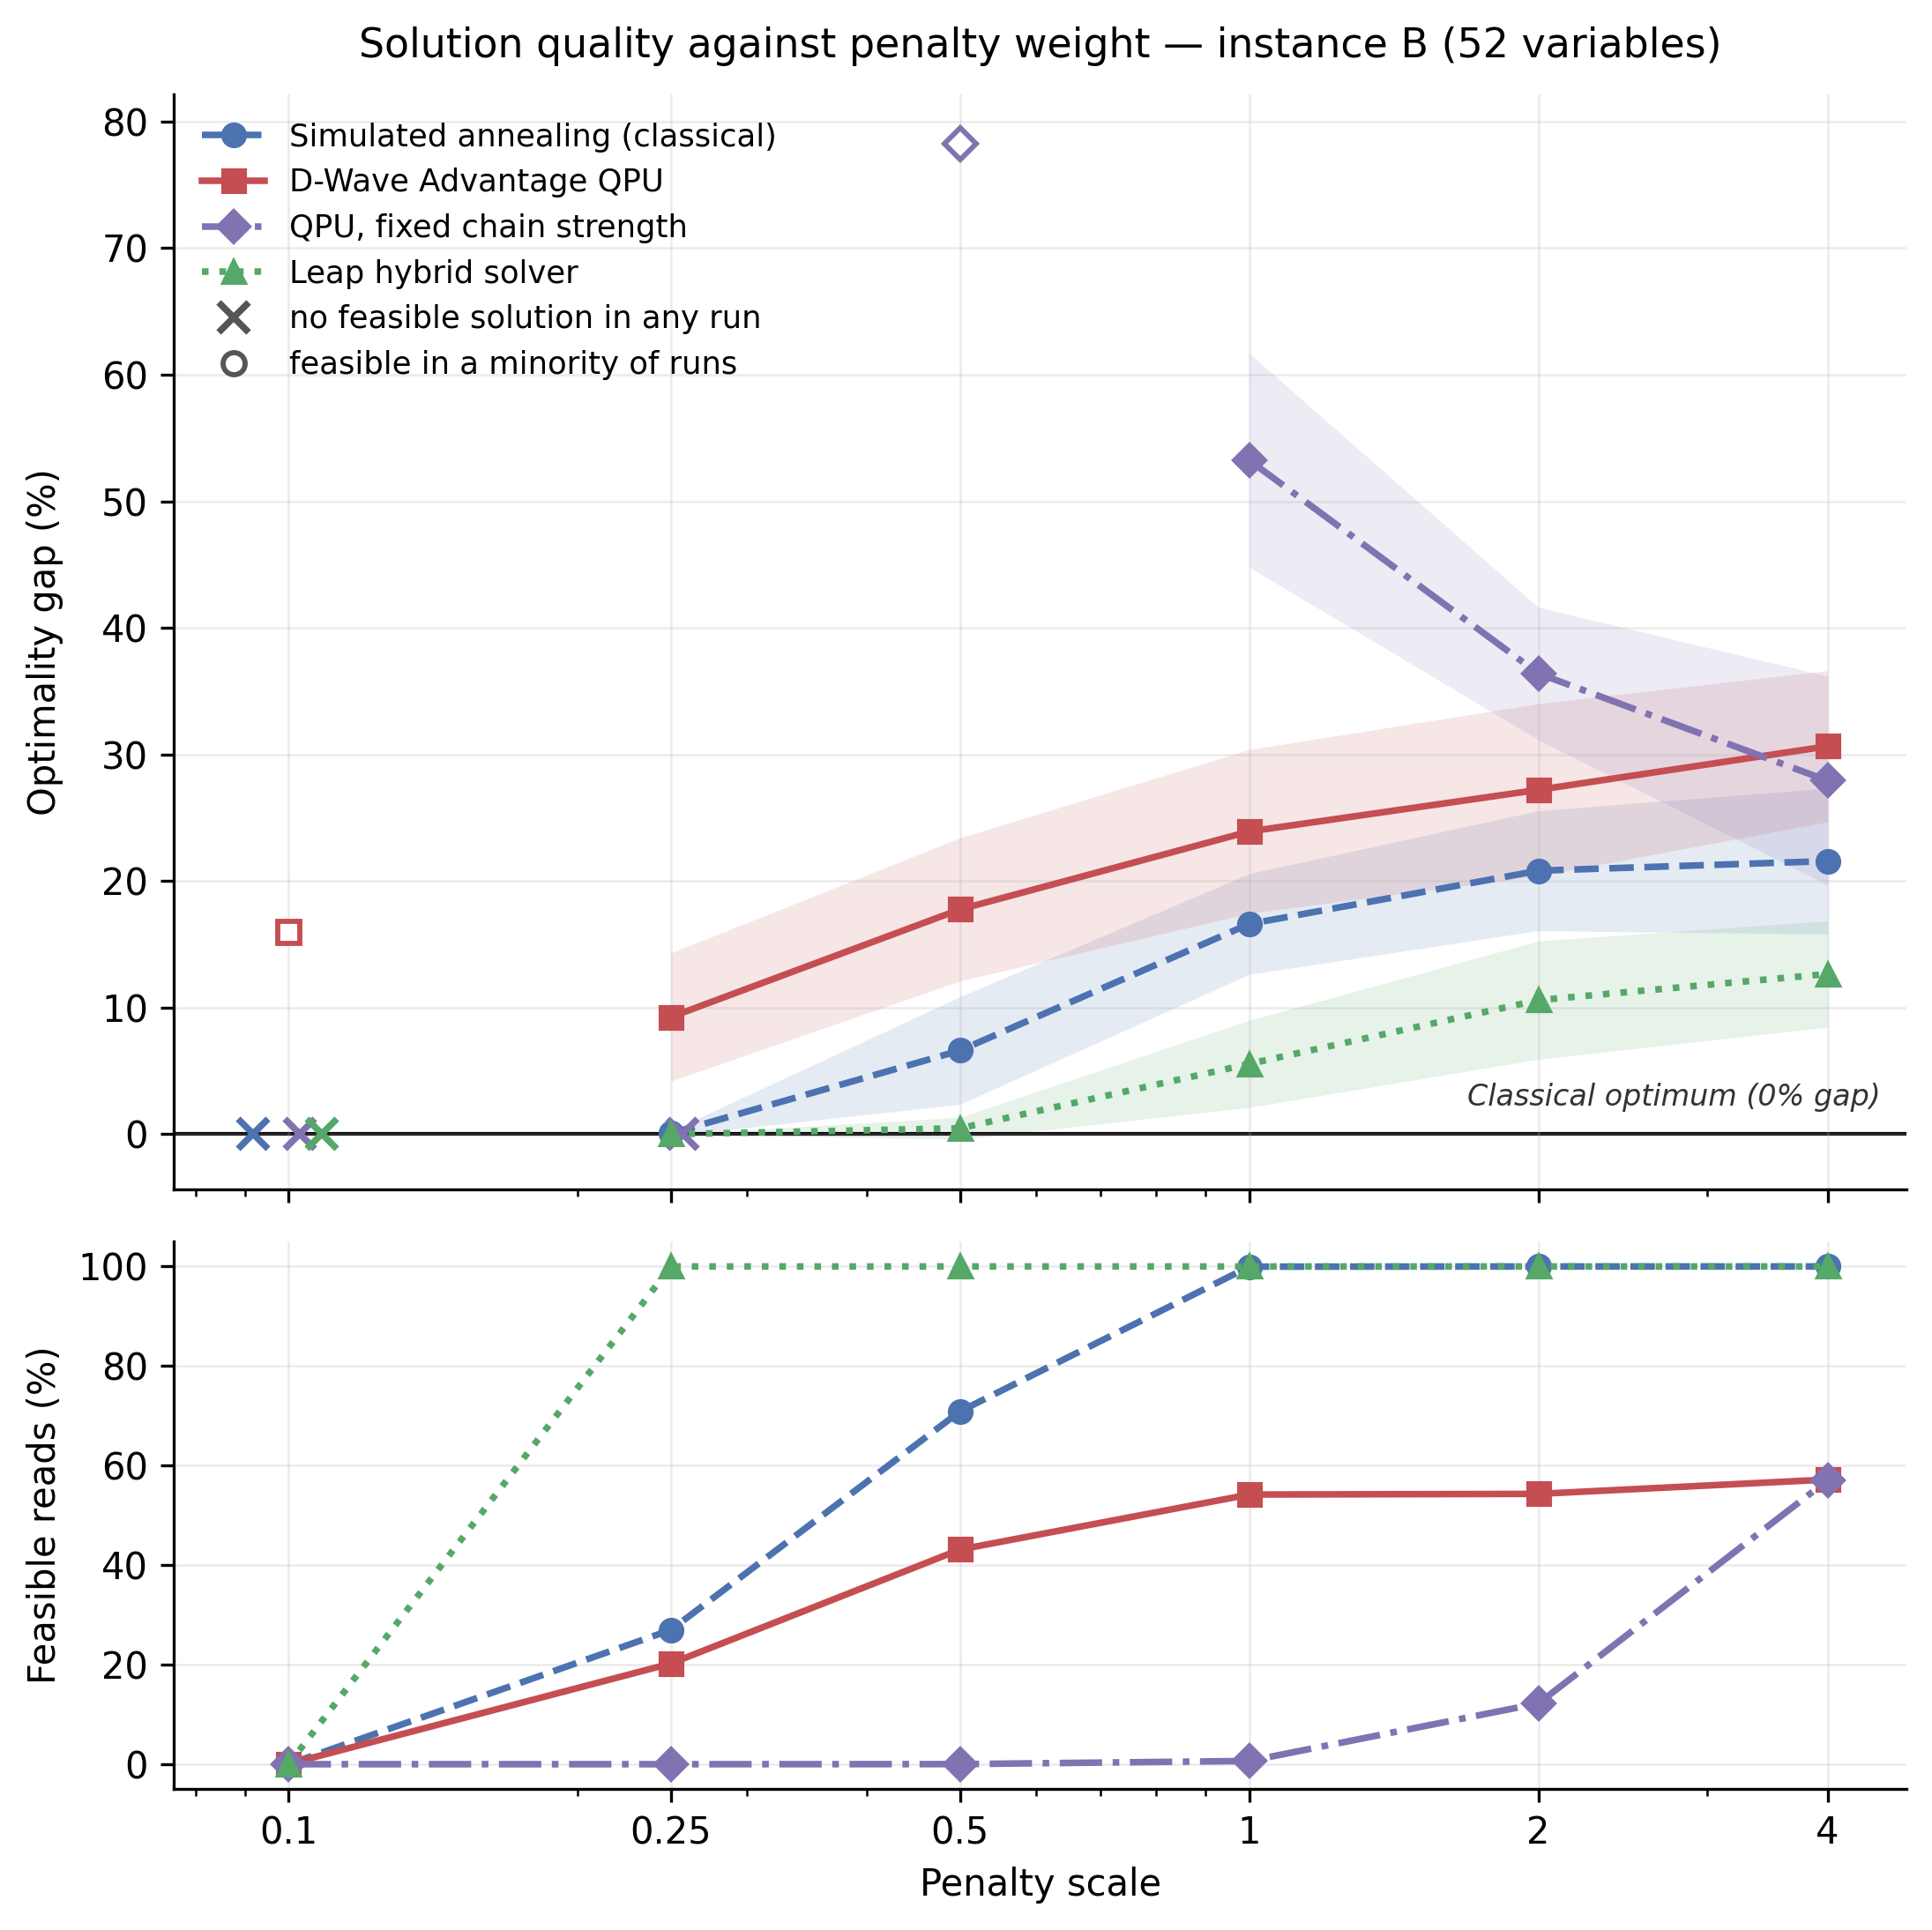

,Solver,Penalty,Runs,Feasible runs,Mean cost (EUR),Mean gap (%),SD (pp),Best (%),Worst (%),Feasible reads (%),Chain breaks (%),QPU time (ms)
0,D-Wave Advantage QPU,0.1,20,8,9571.0,16.0,9.3,3.5,26.8,0.0,0.0,130.8
1,D-Wave Advantage QPU,0.25,20,20,9017.0,9.3,5.1,0.0,17.8,20.0,0.0,129.0
2,D-Wave Advantage QPU,0.5,20,20,9719.0,17.8,5.7,5.5,23.6,43.0,0.0,127.3
3,D-Wave Advantage QPU,1,20,20,10227.0,23.9,6.5,8.4,33.1,54.0,0.0,123.8
4,D-Wave Advantage QPU,2,20,20,10499.0,27.2,6.8,11.9,35.5,54.0,0.0,123.0
5,D-Wave Advantage QPU,4,20,20,10783.0,30.6,6.0,16.5,40.1,57.0,0.0,127.3
6,Leap hybrid solver,0.1,6,0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
7,Leap hybrid solver,0.25,6,6,8253.0,0.0,0.0,0.0,0.0,100.0,NaN,NaN
8,Leap hybrid solver,0.5,6,6,8292.0,0.5,0.9,0.0,2.2,100.0,NaN,NaN
9,Leap hybrid solver,1,6,6,8712.0,5.6,3.4,1.5,11.0,100.0,NaN,NaN


,Instance,Variables,Solver,Replications,Best penalty,Best gap (%),Worst penalty,Worst gap (%),Spread (pp)
0,A,27,D-Wave Advantage QPU,60,0.25,0.0,4,7.7,7.7
1,A,27,Simulated annealing (classical),20,0.25,0.0,4,3.1,3.1
2,B,52,D-Wave Advantage QPU,20,0.25,9.3,4,30.6,21.4
3,B,52,Leap hybrid solver,6,0.25,0.0,4,12.7,12.7
4,B,52,"QPU, fixed chain strength",20,4,27.9,0.5,78.2,50.3
5,B,52,Simulated annealing (classical),20,0.25,0.1,4,21.6,21.5
6,C,105,D-Wave Advantage QPU,40,0.1,22.5,4,36.5,14.0
7,C,105,Simulated annealing (classical),20,0.25,12.2,4,32.7,20.5


,n_vars,qubits,max_chain,breaks,qubits_per_var
instance,,,,,
A,27,32.33,3.0,0.0,1.20
B,52,78.06,7.0,0.0,1.50
C,105,198.43,11.0,0.0,1.89


\begin{tabular}{llrrrrrrrrrr}
\toprule
Solver & Penalty & Runs & Feasible runs & Mean cost (EUR) & Mean gap (%) & SD (pp) & Best (%) & Worst (%) & Feasible reads (%) & Chain breaks (%) & QPU time (ms) \\
\midrule
D-Wave Advantage QPU & 0.1 & 20 & 8 & 9571.0 & 16.0 & 9.3 & 3.5 & 26.8 & 0.0 & 0.0 & 130.8 \\
D-Wave Advantage QPU & 0.25 & 20 & 20 & 9017.0 & 9.3 & 5.1 & 0.0 & 17.8 & 20.0 & 0.0 & 129.0 \\
D-Wave Advantage QPU & 0.5 & 20 & 20 & 9719.0 & 17.8 & 5.7 & 5.5 & 23.6 & 43.0 & 0.0 & 127.3 \\
D-Wave Advantage QPU & 1 & 20 & 20 & 10227.0 & 23.9 & 6.5 & 8.4 & 33.1 & 54.0 & 0.0 & 123.8 \\
D-Wave Advantage QPU & 2 & 20 & 20 & 10499.0 & 27.2 & 6.8 & 11.9 & 35.5 & 54.0 & 0.0 & 123.0 \\
D-Wave Advantage QPU & 4 & 20 & 20 & 10783.0 & 30.6 & 6.0 & 16.5 & 40.1 & 57.0 & 0.0 & 127.3 \\
Leap hybrid solver & 0.1 & 6 & 0 & -- & -- & -- & -- & -- & 0.0 & -- & -- \\
Leap hybrid solver & 0.25 & 6 & 6 & 8253.0 & 0.0 & 0.0 & 0.0 & 0.0 & 100.0 & -- & -- \\
Leap hybrid solver & 0.5 & 6 & 6 & 8292.0 & 0.5 &

In [ ]:
SOLVER_LABEL = {"sa": "Simulated annealing (classical)",
                "qpu": "D-Wave Advantage QPU",
                "qpu_fixed_chain": "QPU, fixed chain strength",
                "hybrid": "Leap hybrid solver"}
STYLE = {"sa":              dict(color="#4C72B0", marker="o", linestyle="--"),
         "qpu":             dict(color="#C44E52", marker="s", linestyle="-"),
         "qpu_fixed_chain": dict(color="#8172B2", marker="D", linestyle="-."),
         "hybrid":          dict(color="#55A868", marker="^", linestyle=":")}
ORDER = ["sa", "qpu", "qpu_fixed_chain", "hybrid"]

def aggregate(df):
    """Cost and gap over FEASIBLE runs only — an infeasible run has no meaningful cost.
    Feasible-read share is over ALL runs, since a run with zero valid reads is data."""
    out = []
    for (inst, solver, ps), s in df.groupby(["instance", "solver", "penalty_scale"]):
        f = s[s.feasible]
        out.append({
            "instance": inst, "solver": solver, "penalty_scale": ps,
            "n_runs": len(s), "n_feasible_runs": len(f),
            "mean_cost": f.best_cost.mean() if len(f) else np.nan,
            "mean_gap":  f.optimality_gap_pct.mean() if len(f) else np.nan,
            "sd_gap":    f.optimality_gap_pct.std()  if len(f) > 1 else np.nan,
            "min_gap":   f.optimality_gap_pct.min()  if len(f) else np.nan,
            "max_gap":   f.optimality_gap_pct.max()  if len(f) else np.nan,
            "feasible_fraction": s.feasible_fraction.mean(),
            "chain_break": s.chain_break_fraction.mean(),
            "qpu_us": s.qpu_access_time_us.mean(),
            "physical_qubits": s.physical_qubits.mean(),
            "max_chain": s.max_chain_length.max()})
    return pd.DataFrame(out)

def figure_1(df, instance="B", path="figure1_penalty_sensitivity.png"):
    from matplotlib.lines import Line2D
    g = aggregate(df); g = g[g.instance == instance]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.4, 7.4), sharex=True,
                                   gridspec_kw={"height_ratios": [2, 1]})
    for solver in ORDER:
        s = g[g.solver == solver].sort_values("penalty_scale")
        if s.empty: continue
        st = STYLE[solver]
        ok = s.dropna(subset=["mean_gap"])
        rel   = ok[ok.n_feasible_runs >= 0.5 * ok.n_runs]
        unrel = ok[ok.n_feasible_runs <  0.5 * ok.n_runs]
        ax1.plot(rel.penalty_scale, rel.mean_gap, label=SOLVER_LABEL[solver],
                 linewidth=1.8, markersize=6, **st)
        if len(unrel):
            ax1.plot(unrel.penalty_scale, unrel.mean_gap, linestyle="none",
                     marker=st["marker"], markersize=6, markerfacecolor="white",
                     markeredgecolor=st["color"], markeredgewidth=1.4)
        if ok.sd_gap.notna().any():
            ax1.fill_between(rel.penalty_scale, rel.mean_gap - rel.sd_gap.fillna(0),
                             rel.mean_gap + rel.sd_gap.fillna(0),
                             color=st["color"], alpha=0.14, linewidth=0)
        dead = s[s.n_feasible_runs == 0]
        if len(dead):
            j = 1.0 + 0.055 * (ORDER.index(solver) - 1.5)   # jitter so series stay visible
            ax1.plot(dead.penalty_scale * j, np.zeros(len(dead)), linestyle="none",
                     marker="x", markersize=8, markeredgewidth=1.8,
                     color=st["color"], clip_on=False)
        ax2.plot(s.penalty_scale, s.feasible_fraction * 100,
                 linewidth=1.8, markersize=6, **st)

    ax1.axhline(0, color="black", linewidth=1.0, zorder=1)
    ax1.annotate("Classical optimum (0% gap)", xy=(0.985, 0.0),
                 xycoords=("axes fraction", "data"), xytext=(0, 6),
                 textcoords="offset points", fontsize=8, style="italic",
                 ha="right", va="bottom", color="#333333")
    n_vars = int(df[df.instance == instance].n_variables.iloc[0])
    ax1.set_ylabel("Optimality gap (%)")
    ax1.set_title(f"Solution quality against penalty weight — instance {instance} "
                  f"({n_vars} variables)", fontsize=11, pad=10)
    ax1.grid(alpha=0.25, linewidth=0.6)
    h, l = ax1.get_legend_handles_labels()
    h += [Line2D([], [], linestyle="none", marker="x", color="#555555",
                 markersize=8, markeredgewidth=1.8),
          Line2D([], [], linestyle="none", marker="o", markerfacecolor="white",
                 markeredgecolor="#555555", markeredgewidth=1.4, markersize=6)]
    l += ["no feasible solution in any run", "feasible in a minority of runs"]
    ax1.legend(h, l, frameon=False, fontsize=8.5, loc="upper left", handletextpad=0.8)
    ax2.set_ylabel("Feasible reads (%)"); ax2.set_xlabel("Penalty scale")
    ax2.set_xscale("log"); ax2.set_ylim(-5, 105); ax2.grid(alpha=0.25, linewidth=0.6)
    ticks = sorted(g.penalty_scale.unique())
    ax2.set_xticks(ticks); ax2.set_xticklabels([f"{t:g}" for t in ticks])
    fig.align_ylabels([ax1, ax2]); fig.tight_layout()
    fig.savefig(path, bbox_inches="tight"); plt.close(fig)
    return path

def table_1(df, instance="B"):
    g = aggregate(df); g = g[g.instance == instance].copy()
    out = pd.DataFrame({
        "Solver": g.solver.map(SOLVER_LABEL),
        "Penalty": g.penalty_scale.map(lambda v: f"{v:g}"),
        "Runs": g.n_runs, "Feasible runs": g.n_feasible_runs,
        "Mean cost (EUR)": g.mean_cost.round(0), "Mean gap (%)": g.mean_gap.round(1),
        "SD (pp)": g.sd_gap.round(1), "Best (%)": g.min_gap.round(1),
        "Worst (%)": g.max_gap.round(1),
        "Feasible reads (%)": (g.feasible_fraction * 100).round(0),
        "Chain breaks (%)": (g.chain_break * 100).round(1),
        "QPU time (ms)": (g.qpu_us / 1000).round(1)})
    return out.sort_values(["Solver", "Penalty"]).reset_index(drop=True)

def table_2(df):
    g = aggregate(df).dropna(subset=["mean_gap"]); rows = []
    for (i, s), x in g.groupby(["instance", "solver"]):
        b, w = x.loc[x.mean_gap.idxmin()], x.loc[x.mean_gap.idxmax()]
        rows.append({"Instance": i,
                     "Variables": int(df[df.instance == i].n_variables.iloc[0]),
                     "Solver": SOLVER_LABEL[s], "Replications": int(x.n_runs.max()),
                     "Best penalty": f"{b.penalty_scale:g}",
                     "Best gap (%)": round(b.mean_gap, 1),
                     "Worst penalty": f"{w.penalty_scale:g}",
                     "Worst gap (%)": round(w.mean_gap, 1),
                     "Spread (pp)": round(w.mean_gap - b.mean_gap, 1)})
    return pd.DataFrame(rows).sort_values(["Instance", "Solver"]).reset_index(drop=True)

# Embedding diagnostics for Section 4.6
emb = df_emb = data[data.solver.str.startswith("qpu")].groupby("instance").agg(
    n_vars=("n_variables", "first"), qubits=("physical_qubits", "mean"),
    max_chain=("max_chain_length", "max"), breaks=("chain_break_fraction", "mean"))
emb["qubits_per_var"] = (emb.qubits / emb.n_vars).round(2)

display(Image(figure_1(data, "B")))
t1 = table_1(data, "B"); display(t1); t1.to_csv("table1_instance_B.csv", index=False)
t2 = table_2(data);      display(t2); t2.to_csv("table2_robustness.csv", index=False)
display(emb.round(2))
print(t1.to_latex(index=False, na_rep="--", float_format="%.1f"))
print(t2.to_latex(index=False, na_rep="--", float_format="%.1f"))

---
## Summary of findings for the thesis

**Chapter 4 (Results) — reported without interpretation:**

1. Reference optima and classical solve times (Step 3)
2. Confirmation that the pipeline executed on quantum hardware, with processor identity and qubit counts
   (Steps 6 and 8)
3. Figure 1, Table 1, Table 2
4. Embedding diagnostics: physical qubits per logical variable, and chain-break rates by instance

**Chapter 5 (Discussion) — interpretation:**

- Solution quality on a fixed instance varies by *[spread, from Table 2]* percentage points as a function of
  penalty weight alone, with solver, hardware, and problem held constant
- Whether the quantum arm degrades more steeply than the classical arm across the penalty range, and what that
  implies about hardware amplifying rather than absorbing formulation error
- That the usable penalty range is narrow and instance-specific, so calibration cannot be omitted
- The implication for the literature: comparative studies that do not document penalty calibration are
  measuring the encoding rather than the solver (Roch et al., 2023)

**Limitations, stated plainly:** one problem class, three small instances, one quantum platform. No claim of
quantum advantage is made or tested; classical methods solve these instances exactly in milliseconds. The
contribution concerns formulation sensitivity as an adoption barrier, not quantum performance.